<a href="https://colab.research.google.com/github/Doop318/business-predictive-analytics/blob/main/Mastering_Bayes'_Theorem_A_Step_by_Step.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Mastering Bayes' Theorem: A Step-by-Step Tutorial

Bayes' Theorem calculates conditional probability—the likelihood of an event occurring based on prior knowledge of conditions related to the event.

---

## 1. The Core Formula Explained Simply

Instead of using confusing abstract labels like $H$ and $x$, we can use intuitive words: **Outcome** (what we want to predict) and **Evidence** (the data we observe).

$$P(\text{Outcome} \mid \text{Evidence}) = \frac{P(\text{Evidence} \mid \text{Outcome}) \times P(\text{Outcome})}{P(\text{Evidence})}$$

* **$P(\text{Outcome} \mid \text{Evidence})$** (Posterior): The probability that our prediction is true *after* looking at the new evidence.
* **$P(\text{Evidence} \mid \text{Outcome})$** (Likelihood): How often do we see this evidence when that outcome is already known to be true?
* **$P(\text{Outcome})$** (Prior): The baseline probability of the outcome before looking at any evidence.
* **$P(\text{Evidence})$** (Marginal): The baseline probability of this evidence occurring across the entire dataset.

---

## 2. Walkthrough Example: Predicting Student Passing Rates

Let's use the actual historical student dataset from your lecture slides:

### The Historical Dataset (5 Students Total)

| Student ID | Assessment 1 | Assessment 2 | Course Outcome |
| :--- | :--- | :--- | :--- |
| **1** | D | HD | **Pass** |
| **2** | P1 | HD | **Pass** |
| **3** | P1 | P1 | **Fail** |
| **4** | P2 | P1 | **Fail** |
| **5** | C | C | **Pass** |

### 🔍 Problem Scenario 1: Single Grade Evidence
**Problem:** If a student gets a **P1 grade** on Assessment 1, what is the probability that they will **Pass** the course?

#### Step 1: Collect your base fractions from the table
* **$P(\text{Pass})$** $= \frac{3}{5} = \mathbf{0.6}$ *(3 out of 5 total students passed: IDs 1, 2, 5)*
* **$P(\text{P1 Grade} \mid \text{Pass})$** $= \frac{1}{3} \approx \mathbf{0.333}$ *(Out of the 3 students who passed, only ID 2 got a P1)*
* **$P(\text{P1 Grade})$** $= \frac{2}{5} = \mathbf{0.4}$ *(2 out of 5 total students got a P1 on Assessment 1: IDs 2, 3)*

#### Step 2: Plug fractions into the formula to avoid rounding errors
$$P(\text{Pass} \mid \text{P1 Grade}) = \frac{\frac{1}{3} \times \frac{3}{5}}{\frac{2}{5}}$$

#### Step 3: Compute the final value
* **Numerator calculation:** $\frac{1}{3} \times 0.6 = 0.2$
* **Final Division:** $\frac{0.2}{0.4} = \mathbf{0.50}$

**Answer:** A student who gets a P1 on Assessment 1 has a **50% chance** of passing the course.

> ⚠️ *Note: Slide 6 incorrectly states **45%** because it prematurely rounded $\frac{1}{3}$ to $0.3$ during execution. Always calculate using exact fractions!*

---

### 🔍 Problem Scenario 2: Multiple Joint Evidences
**Problem:** Given a new student profile with the specific instance **{Assessment 1 = P1, Assessment 2 = HD}**, what is the probability they will **Pass**?

When dealing with a combination of attributes, we treat the combination as a single compound evidence element.

#### Step 1: Collect your base fractions from the table
* **$P(\text{Pass})$** $= \frac{3}{5} = \mathbf{0.6}$ *(3 out of 5 total students passed)*
* **$P(\text{P1 and HD} \mid \text{Pass})$** $= \frac{1}{3} \approx \mathbf{0.333}$ *(Out of the 3 passing students, only student ID 2 had the exact combination of P1 and HD)*
* **$P(\text{P1 and HD})$** $= \frac{1}{5} = \mathbf{0.2}$ *(Out of all 5 entries, only student ID 2 has this exact grade pair)*

#### Step 2: Run the calculation
$$P(\text{Pass} \mid \text{P1 and HD}) = \frac{P(\text{P1 and HD} \mid \text{Pass}) \times P(\text{Pass})}{P(\text{P1 and HD})}$$

$$P(\text{Pass} \mid \text{P1 and HD}) = \frac{\frac{1}{3} \times \frac{3}{5}}{\frac{1}{5}} = \frac{0.2}{0.2} = \mathbf{1.0}$$

**Answer:** There is a **100% chance** a student with this specific pattern will pass, completely verified by observing that student ID 2 matches the profile exactly and passed.

---

## 3. The "Common Sense" Shortcut (Frequentist Method)
You can easily check your Bayes' Theorem answers instantly without using formulas by using the **filter approach**:

1. **Isolate the evidence rows:** Look only at rows matching the condition you know occurred.
2. **Count the target outcome:** Find out how many of those isolated rows achieved your preferred outcome.

*For Scenario 1:* Filter for Assessment 1 = P1 $\rightarrow$ (Finds IDs 2, 3 = **2 students**). How many passed? Only 1 (ID 2). Result = $\frac{1}{2} = \mathbf{50\%}$.


In [8]:
import pandas as pd

# 1. Recreate the dataset from the slides
data = {
    'ID': [1, 2, 3, 4, 5],
    'Ass1': ['D', 'P1', 'P1', 'P2', 'C'],
    'Ass2': ['HD', 'HD', 'P1', 'P1', 'C'],
    'Grade': ['P', 'P', 'F', 'F', 'P']
}

print(data)

{'ID': [1, 2, 3, 4, 5], 'Ass1': ['D', 'P1', 'P1', 'P2', 'C'], 'Ass2': ['HD', 'HD', 'P1', 'P1', 'C'], 'Grade': ['P', 'P', 'F', 'F', 'P']}



💻 **Python Code to Generate This Table**

To transform your dictionary into a table format using pandas, pass the dictionary to pd.DataFrame():

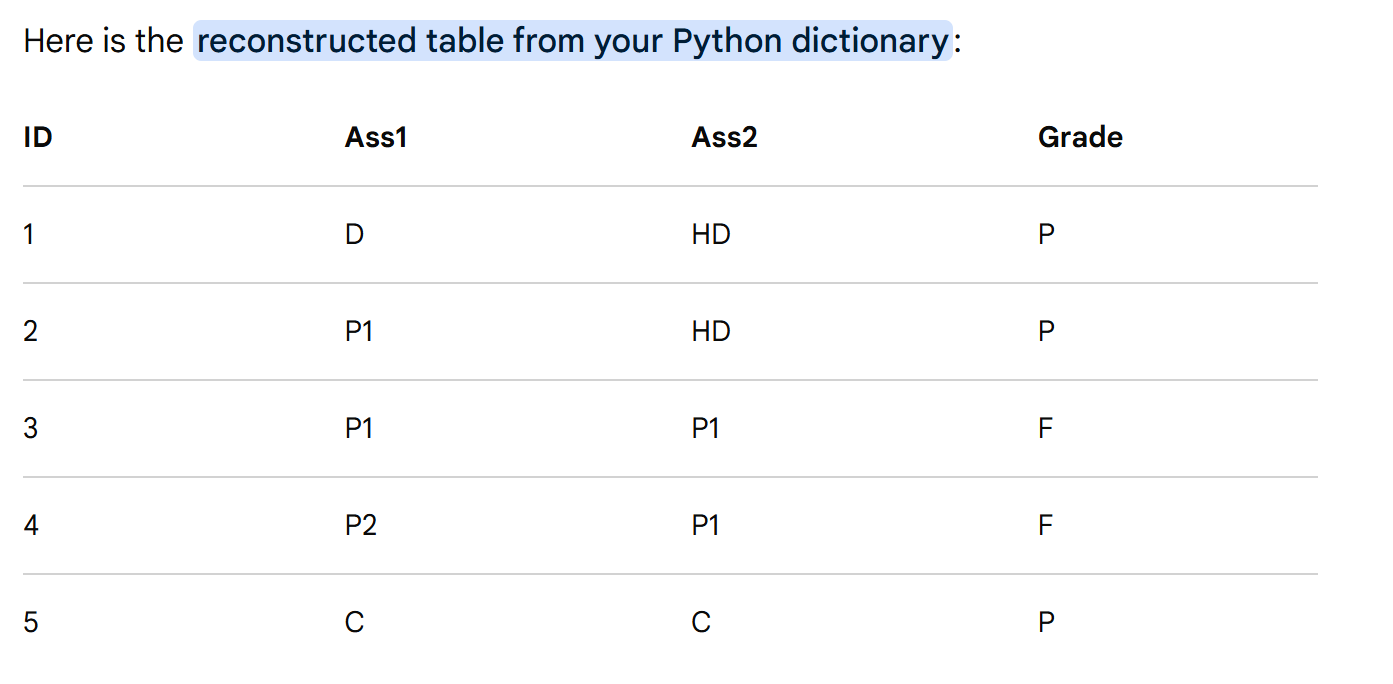

In [9]:
# Convert the dictionary to a DataFrame
df = pd.DataFrame(data)

# Print the tabular layout
print(df.to_string(index=False))

 ID Ass1 Ass2 Grade
  1    D   HD     P
  2   P1   HD     P
  3   P1   P1     F
  4   P2   P1     F
  5    C    C     P


In [10]:
def calculate_bayes(ass1_val, ass2_val, target_class = "P"):
  total_students = len(df)

  # Prior: P(Target Class)
  prior_target = len(df[df["Grade"] == target_class]) / total_students

  # Joint Evidence / Marginal: P(Ass1 & Ass2)
  marginal_evidence = len(df[(df["Ass1"] == ass1_val) & (df["Ass2"] == ass2_val)]) / total_students

  # Check if evidence exists in dataset to avoid Division by Zero
  if marginal_evidence == 0:
    return f"P({target_class} | {ass1_val}, {ass2_val}) is Undefined (Evidence count is 0). Need Naive Bayes!"

  # Likelihood: P(Ass1 & Ass2 | Target Class)
  target_students = df[df["Grade"] == target_class]
  likelihood = len(target_students[(target_students["Ass1"] == ass1_val) & (target_students["Ass2"] == ass2_val)]) / len(target_students)

  # Bayes Theorem Equation
  posterior = (likelihood * prior_target) / marginal_evidence

  return f"P({target_class} | {ass1_val}, {ass2_val}) = {posterior:.2f}"

# Test Scenario 2 (Slide 8)
print("Scenario 2 Check:", calculate_bayes('P1', 'HD'))

# Test Slide 9 Unsolved Problem
print("Slide 9 Check:", calculate_bayes('P1', 'C'))

Scenario 2 Check: P(P | P1, HD) = 1.00
Slide 9 Check: P(P | P1, C) is Undefined (Evidence count is 0). Need Naive Bayes!


### 🧠 Solving the Unsolved Problem (Slide 9) Using Naive Bayes

**Problem:** Given a test instance where **Assessment 1 = P1** and **Assessment 2 = C**, what is the probability that the student will **Pass** ($P$) versus **Fail** ($F$)?

As established before, standard Bayes' Theorem hits a division-by-zero lock because the combination `{P1, C}` never appears in our dataset.

#### The Naive Bayes Solution
To bypass this, Naive Bayes makes a "naive" assumption: **Assessment 1 and Assessment 2 grades are independent given the class outcome.**

Instead of looking for the joint combination $P(\text{P1 and C} \mid \text{Class})$, we break it apart and multiply the individual attribute probabilities:

$$P(\text{P1}, \text{C} \mid \text{Class}) = P(\text{P1} \mid \text{Class}) \times P(\text{C} \mid \text{Class})$$

---

#### Step 1: Calculate the Probabilities for Class = Pass ($P$)

1. **Prior Probability:**
   $$P(H = P) = \frac{3}{5} = 0.6$$

2. **Independent Likelihoods for Passing Students (IDs 1, 2, 5):**
   * Out of the 3 passing students, how many got a **P1** on Assessment 1? Only ID 2.
     $$P(\text{P1} \mid H = P) = \frac{1}{3}$$
   * Out of the 3 passing students, how many got a **C** on Assessment 2? Only ID 5.
     $$P(\text{C} \mid H = P) = \frac{1}{3}$$

3. **Combined Numerator for Pass:**
   $$\text{Score}(P) = P(\text{P1} \mid H = P) \times P(\text{C} \mid H = P) \times P(H = P)$$
   $$\text{Score}(P) = \frac{1}{3} \times \frac{1}{3} \times \frac{3}{5} = \frac{3}{45} = \mathbf{0.0667}$$

---

#### Step 2: Calculate the Probabilities for Class = Fail ($F$)

1. **Prior Probability:**
   $$P(H = F) = \frac{2}{5} = 0.4$$

2. **Independent Likelihoods for Failing Students (IDs 3, 4):**
   * Out of the 2 failing students, how many got a **P1** on Assessment 1? Only ID 3.
     $$P(\text{P1} \mid H = F) = \frac{1}{2} = 0.5$$
   * Out of the 2 failing students, how many got a **C** on Assessment 2? None.
     $$P(\text{C} \mid H = F) = \frac{0}{2} = 0$$

3. **Combined Numerator for Fail:**
   $$\text{Score}(F) = P(\text{P1} \mid H = F) \times P(\text{C} \mid H = F) \times P(H = F)$$
   $$\text{Score}(F) = 0.5 \times 0 \times 0.4 = \mathbf{0}$$

---

#### Step 3: Normalisation (Maximum A Posteriori - MAP)

To get the final probabilities, we scale both scores so they add up to 100%:

$$P(H = P \mid \text{P1}, \text{C}) = \frac{\text{Score}(P)}{\text{Score}(P) + \text{Score}(F)} = \frac{0.0667}{0.0667 + 0} = \mathbf{1.0 \text{ (100\%)}}$$

**Final Conclusion:** Using Naive Bayes, a student with the profile **{P1, C}** has a **100% probability of passing** the course.

In [15]:
import pandas as pd

# Recreate the dataset from the slides
data = {
    'ID': [1, 2, 3, 4, 5],
    'Ass1': ['D', 'P1', 'P1', 'P2', 'C'],
    'Ass2': ['HD', 'HD', 'P1', 'P1', 'C'],
    'Class': ['P', 'P', 'F', 'F', 'P']
}
df = pd.DataFrame(data)

def naive_bayes_predict(ass1_val, ass2_val):
    total_entries = len(df)
    classes = df['Class'].unique()
    scores = {}

    print(f"--- Naive Bayes Analysis for Profile: {{Ass1: {ass1_val}, Ass2: {ass2_val}}} ---")

    for c in classes:
        # 1. P(Class)
        df_class = df[df['Class'] == c]
        p_class = len(df_class) / total_entries

        # 2. P(Ass1 | Class)
        p_ass1_given_class = len(df_class[df_class['Ass1'] == ass1_val]) / len(df_class)

        # 3. P(Ass2 | Class)
        p_ass2_given_class = len(df_class[df_class['Ass2'] == ass2_val]) / len(df_class)

        # Combined Score (Numerator)
        score = p_ass1_given_class * p_ass2_given_class * p_class
        scores[c] = score

        print(f"Class {c} -> P(Class)={p_class:.2f}, P({ass1_val}|{c})={p_ass1_given_class:.3f}, P({ass2_val}|{c})={p_ass2_given_class:.3f} | Score = {score:.4f}")

    # Normalise values to map to true probabilities
    total_score = sum(scores.values())
    if total_score == 0:
        return "Both options evaluated to 0. Absolute zero probability lock achieved."

    probabilities = {c: score / total_score for c, score in scores.items()}
    return f"\nFinal Probabilities -> {probabilities}"

# Solve Slide 9 Unsolved Problem
print(naive_bayes_predict('P1', 'C'))

--- Naive Bayes Analysis for Profile: {Ass1: P1, Ass2: C} ---
Class P -> P(Class)=0.60, P(P1|P)=0.333, P(C|P)=0.333 | Score = 0.0667
Class F -> P(Class)=0.40, P(P1|F)=0.500, P(C|F)=0.000 | Score = 0.0000

Final Probabilities -> {'P': 1.0, 'F': 0.0}


Here is the **complete Python code** using scikit-learn to `automate the Naive Bayes prediction` on your dataset.

Because your data contains categorical features `(D, P1, P2, C)`, we need to encode them numerically using OrdinalEncoder or OneHotEncoder before training scikit-learn's **CategoricalNB** classifier.

In [17]:
import pandas as pd
from sklearn.preprocessing import OrdinalEncoder
from sklearn.naive_bayes import CategoricalNB

# 1. Recreate the dataset
data = {
    'ID': [1, 2, 3, 4, 5],
    'Ass1': ['D', 'P1', 'P1', 'P2', 'C'],
    'Ass2': ['HD', 'HD', 'P1', 'P1', 'C'],
    'Grade': ['P', 'P', 'F', 'F', 'P']
}
df = pd.DataFrame(data)

# 2. Separate features (X) and target label (y)
X_categorical = df[['Ass1', 'Ass2']]
y = df['Grade']

# 3. Encode categorical features into integer numbers
# (scikit-learn classifiers require numerical inputs)
encoder = OrdinalEncoder()
X_encoded = encoder.fit_transform(X_categorical)

# 4. Initialize and fit the Categorical Naive Bayes model
# Note: scikit-learn's CategoricalNB automatically applies Laplace smoothing (alpha=1.0)
model = CategoricalNB(alpha=1.0)
model.fit(X_encoded, y)

# 5. Prepare the new student data for prediction: Ass1 = 'P1', Ass2 = 'P1'
new_student = pd.DataFrame([['P1', 'P1']], columns=['Ass1', 'Ass2'])
new_student_encoded = encoder.transform(new_student)

# 6. Run prediction and find probabilities
prediction = model.predict(new_student_encoded)
probabilities = model.predict_proba(new_student_encoded)

# 7. Display Results
print(f"Predicted Grade for [Ass1=P1, Ass2=P1]: {prediction[0]}")
print(f"Prediction Probabilities ({model.classes_}): {probabilities[0]}")

Predicted Grade for [Ass1=P1, Ass2=P1]: F
Prediction Probabilities (['F' 'P']): [0.73684211 0.26315789]
